# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
# TODO 1: one 1080p RGB frame, in MB
MB = 1024 ** 2
frame_mb = (1920 * 1080 * 3 * 8) / 8 / MB     # W x H x C bytes (8 bits/channel = 1 byte/channel)

# TODO 2: frames per camera per day at 30 fps
frames_per_day = FPS * 24 * 3600

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
TB = 1024 ** 4
fleet_bytes = 400 * (1920 * 1080 * 3) * frames_per_day
fleet_tb = fleet_bytes / TB

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
frames_per_day_small = 10 * 24 * 3600
fleet_bytes_small = 400 * (640 * 360 * 3) * frames_per_day_small
fleet_tb_small = fleet_bytes_small / TB
pct_pixels_remaining = (640 * 360) / (1920 * 1080) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")


One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_ Spatially, dropping to 640x360 means a face or a licence plate that only ever occupies a few
raw pixels at 1080p is rasterized into a handful of blurred samples at 360p — interpolation on playback cannot
reinvent detail that was never captured, so a readable plate number could become permanently illegible.
Temporally, 10 fps leaves a 100 ms gap between samples; the correspondence problem means a fast action (a punch,
a weapon being drawn, glass shattering) can happen entirely between two sampled frames, so the event itself —
not just its sharpness — can simply never appear in the footage at all.


## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

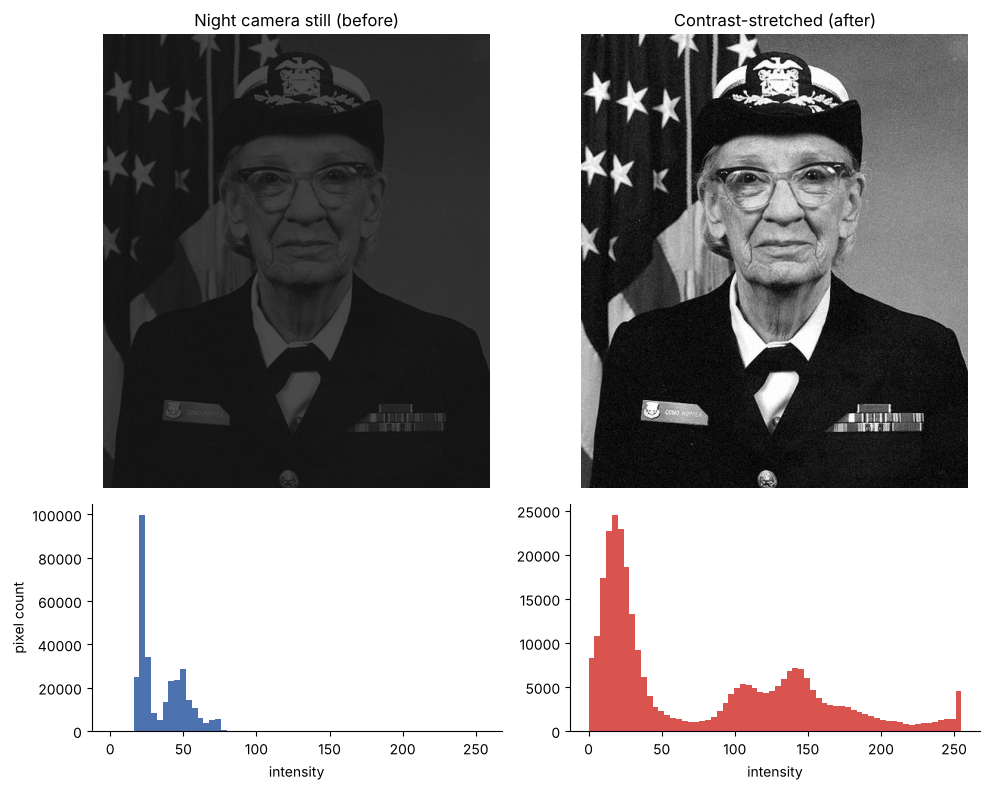

Contrast before: 0.609  ->  after: 1.000


In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
lo_p, hi_p = np.percentile(night_still, [1, 99])
c_before = michelson(hi_p, lo_p)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip((night_still - lo_p) / (hi_p - lo_p) * 255, 0, 255)

lo_p2, hi_p2 = np.percentile(stretched, [1, 99])
c_after = michelson(hi_p2, lo_p2)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255); axes[0, 0].axis("off")
axes[0, 0].set_title("Night camera still (before)")
axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255); axes[0, 1].axis("off")
axes[0, 1].set_title("Contrast-stretched (after)")
axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color="#4C72B0")
axes[1, 0].set_xlabel("intensity"); axes[1, 0].set_ylabel("pixel count")
axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color="#D9534F")
axes[1, 1].set_xlabel("intensity")

plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")


**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_ The night image's histogram is a narrow, low-key peak — almost all pixel values are crammed into a
small dark band near the low end of the 0-255 range, which is exactly the "underexposed / low contrast" shape from
the lecture's table. Stretching made it readable by remapping that narrow occupied range back onto the full 0-255
scale, so differences that were already there but compressed into a few adjacent grey levels become visually
distinguishable — no new measurements were added, the existing ones were just spread out. A histogram alone could
never tell us what's in the picture because it only records how many pixels have each intensity, throwing away
every pixel's (x, y) position — the same histogram can belong to a sharp portrait or to a random scatter of noise
("Same Histogram ≠ Same Image"), so spatial arrangement, not the intensity count, is what carries the content.


## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

standing: t = 68.87 s  ->  70.53 s
standing: t = 77.00 s  ->  78.10 s
 running: t = 78.60 s  ->  86.00 s

audio_event_idx = 2250 (t = 75.0 s)
lighting_event_idx = 3000 (t = 100.0 s)


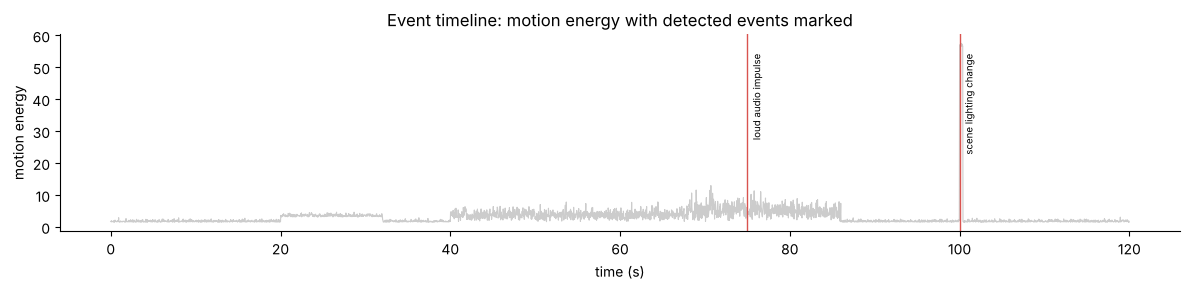

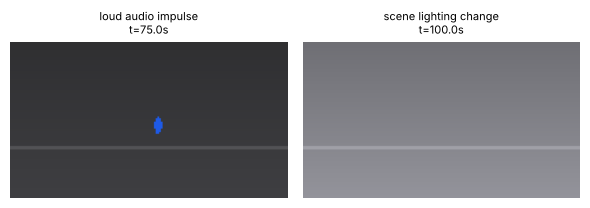

In [4]:
# TODO 1: person speed (px/s)
speed = np.hypot(cctv.person_x.diff(FPS), cctv.person_y.diff(FPS))

# TODO 2: standing / running time ranges (print the first and last time of each)
state = pd.cut(speed, [-0.1, 3, 25, np.inf], labels=["standing", "walking", "running"])
seg = state.astype(object).where(state.notna())
run_id = seg.ne(seg.shift()).cumsum()
seg = seg.where(seg.groupby(run_id).transform("size") >= FPS)          # drop runs shorter than 1 s (jitter)
run_id = seg.ne(seg.shift()).cumsum()

for which in ["standing", "running"]:
    mask = seg == which
    for _, grp in cctv.loc[mask].groupby(run_id[mask]):
        print(f"{which:>8}: t = {grp.time_s.iloc[0]:.2f} s  ->  {grp.time_s.iloc[-1]:.2f} s")

# TODO 3: event frame indices
loud = cctv.index[(cctv.audio_level_db > -20) & (cctv.audio_level_db.shift() <= -20)]
audio_event_idx = int(loud[0]) if len(loud) else None

bright_jump = cctv.index[cctv.mean_brightness.diff() > 40]
lighting_event_idx = int(bright_jump[0]) if len(bright_jump) else None

print(f"\naudio_event_idx = {audio_event_idx} (t = {cctv.time_s[audio_event_idx]:.1f} s)")
print(f"lighting_event_idx = {lighting_event_idx} (t = {cctv.time_s[lighting_event_idx]:.1f} s)")

# TODO 4: annotated motion-energy timeline
events = [("loud audio impulse", audio_event_idx), ("scene lighting change", lighting_event_idx)]
run_changes = seg.index[seg.ne(seg.shift()) & seg.notna() & seg.shift().notna()]
for i in run_changes:
    events.append((f"person starts {seg[i]}", i))
events = sorted(events, key=lambda e: cctv.time_s[e[1]])

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv.time_s, cctv.motion_energy, color="#cccccc", lw=0.8)
for name, i in events:
    color = "#D9534F" if ("audio" in name or "lighting" in name) else "#4C72B0"
    ax.axvline(cctv.time_s[i], color=color, lw=1)
    ax.text(cctv.time_s[i] + 0.4, ax.get_ylim()[1] * 0.9, name, rotation=90, va="top", fontsize=7)
ax.set_xlabel("time (s)"); ax.set_ylabel("motion energy")
ax.set_title("Event timeline: motion energy with detected events marked")
plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
fig, axes = plt.subplots(1, len(events), figsize=(3 * len(events), 3))
for ax, (name, i) in zip(axes, events):
    ax.imshow(render_frame(cctv.iloc[i])); ax.axis("off")
    ax.set_title(f"{name}\nt={cctv.time_s[i]:.1f}s", fontsize=8)
plt.tight_layout(); plt.show()


**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_ Uniform keyframes every 20 s would almost certainly miss the loud audio impulse and the person's
transition into running, because both are short-lived events that can land anywhere inside a 20-second gap between
samples — a fixed, content-blind schedule has no way to "notice" that something happened between two of its
checkpoints. The approach used here instead is **content-based keyframe selection** (Slide 40): keyframes are
chosen at the moments where the data itself signals a change (a motion-energy peak, an audio or brightness jump),
so sparse but important events are never skipped over.


## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

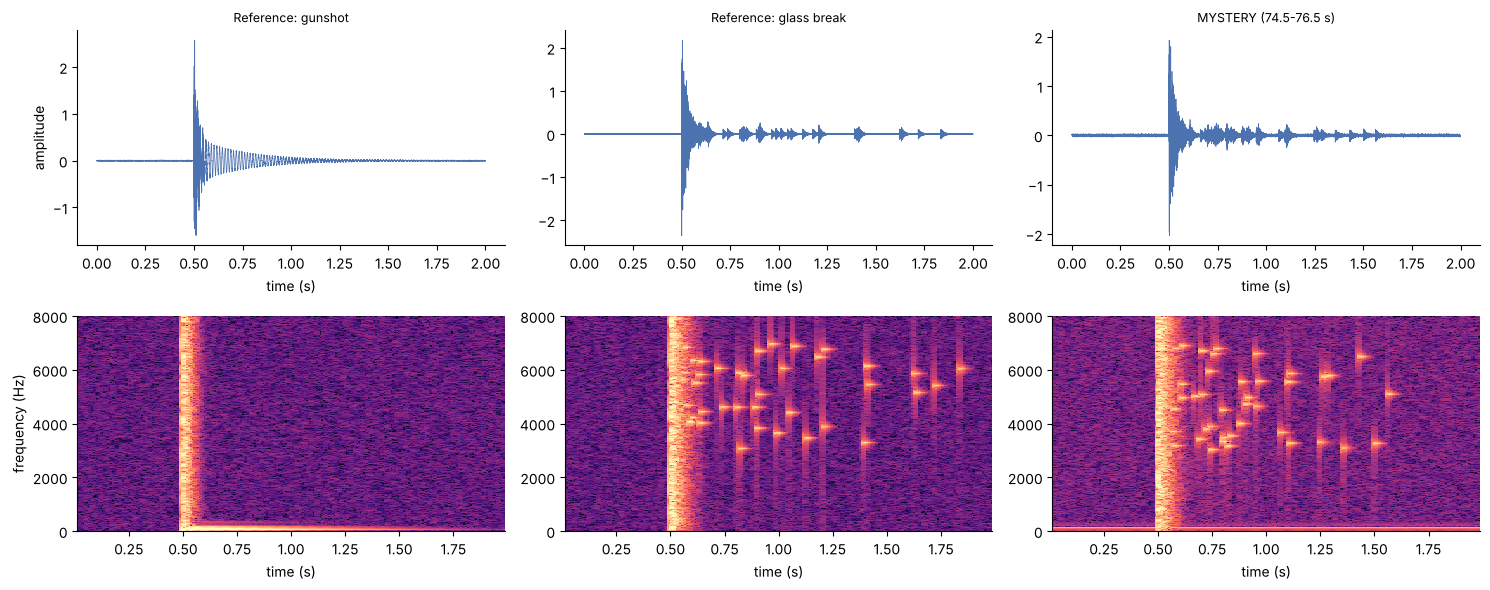

{'Reference: gunshot': np.float64(0.0030352610136762815), 'Reference: glass break': np.float64(0.9891874044148661), 'MYSTERY (74.5-76.5 s)': np.float64(0.8734552491106997)}
Verdict: the mystery sound's high-frequency fraction (0.87) is closest to the glass break reference (gunshot=0.00, glass=0.99) -> classified as GLASS BREAK.


In [5]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
for col, (name, clip) in enumerate(clips.items()):
    t_clip = np.arange(clip.size) / FS
    axes[0, col].plot(t_clip, clip, lw=0.5, color="#4C72B0")
    axes[0, col].set_title(name, fontsize=9)
    axes[0, col].set_xlabel("time (s)")

    f, tt, Sxx = signal.spectrogram(clip, fs=FS, nperseg=512, noverlap=384)
    pcm = axes[1, col].pcolormesh(tt, f, 10 * np.log10(Sxx + 1e-12), shading="auto", cmap="magma", vmin=-110, vmax=-40)
    axes[1, col].set_ylim(0, 8000)
    axes[1, col].set_xlabel("time (s)")
axes[0, 0].set_ylabel("amplitude")
axes[1, 0].set_ylabel("frequency (Hz)")
plt.tight_layout(); plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
hf_fraction = {}
for name, clip in clips.items():
    f, tt, Sxx = signal.spectrogram(clip, fs=FS, nperseg=512, noverlap=384)
    window = (tt >= 0.7) & (tt <= 1.7)                 # 0.2-1.2 s after the impact at t=0.5 s
    Sxx_win = Sxx[:, window]
    hf_fraction[name] = Sxx_win[f > 3000].sum() / Sxx_win.sum()

print(hf_fraction)
# TODO 4: verdict
mystery_hf, gunshot_hf, glass_hf = hf_fraction["MYSTERY (74.5-76.5 s)"], hf_fraction["Reference: gunshot"], hf_fraction["Reference: glass break"]
verdict = "GLASS BREAK" if abs(mystery_hf - glass_hf) < abs(mystery_hf - gunshot_hf) else "GUNSHOT"
print(f"Verdict: the mystery sound's high-frequency fraction ({mystery_hf:.2f}) is closest to the {verdict.lower()} "
      f"reference (gunshot={gunshot_hf:.2f}, glass={glass_hf:.2f}) -> classified as {verdict}.")


**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_ No — all three waveforms look like the same kind of sharp broadband spike at the moment of impact
followed by some decaying wiggle; amplitude alone can't separate a gunshot from a glass break. The spectrogram adds
the three dimensions from Slide 57 — time, frequency and magnitude (shown as colour) — all at once, so it shows not
just *when* something loud happened but *what frequencies* it was made of over time. The decision came down to a
pattern of **scattered high-frequency specks** lingering for a few hundred milliseconds in the 3-7 kHz range after
the impact in the mystery clip and the glass reference (the "tinkle" of shards), versus a clean broadband crack with
a low-frequency boom and nothing afterward in the gunshot reference.


## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

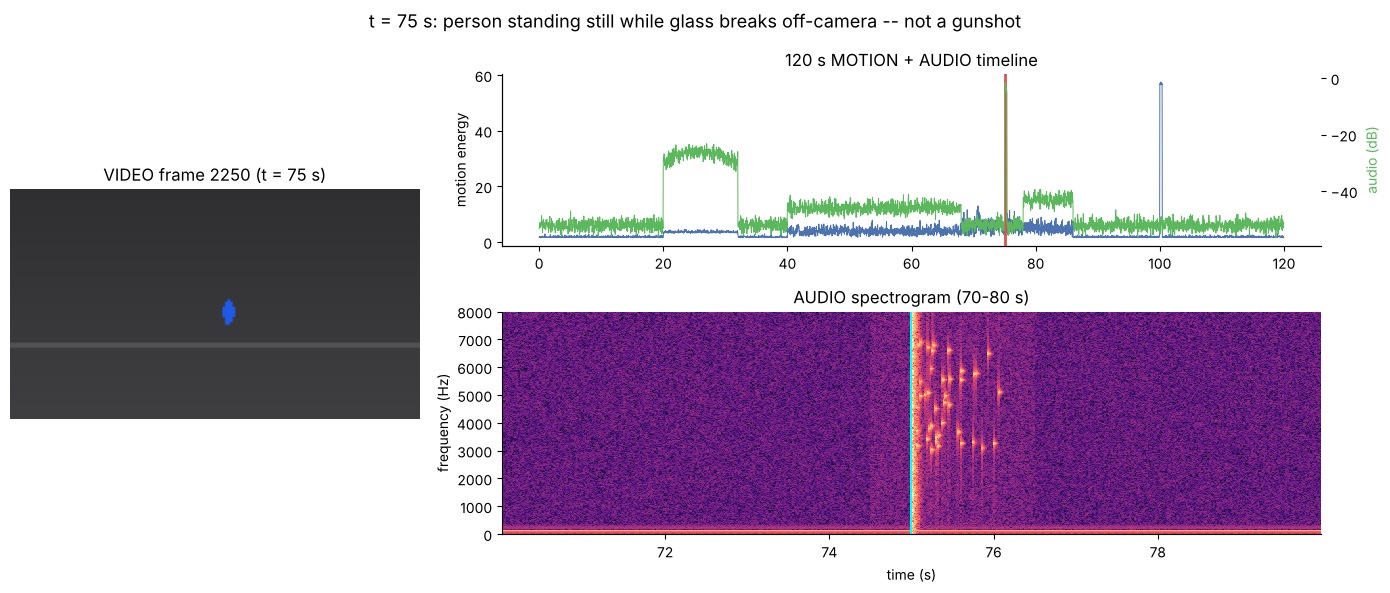

In [6]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
# TODO 1-4
i_sel = int(round(t_sel * FPS))

ax_frame = fig.add_subplot(gs[:, 0])
ax_frame.imshow(render_frame(cctv.iloc[i_sel])); ax_frame.axis("off")
ax_frame.set_title(f"VIDEO frame {i_sel} (t = {t_sel:.0f} s)")

ax_time = fig.add_subplot(gs[0, 1])
ax_time.plot(cctv.time_s, cctv.motion_energy, color="#4C72B0", lw=0.7, label="motion")
ax_time2 = ax_time.twinx()
ax_time2.plot(cctv.time_s, cctv.audio_level_db, color="#5cb85c", lw=0.7)
ax_time.axvline(t_sel, color="#D9534F", lw=2)
ax_time.set_ylabel("motion energy"); ax_time2.set_ylabel("audio (dB)", color="#5cb85c")
ax_time.set_title("120 s MOTION + AUDIO timeline")

ax_spec = fig.add_subplot(gs[1, 1])
f, tt, Sxx = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
ax_spec.pcolormesh(tt + t_audio[0], f, 10 * np.log10(Sxx + 1e-12), shading="auto", cmap="magma", vmin=-110, vmax=-40)
ax_spec.axvline(t_sel, color="cyan", lw=1.5)
ax_spec.set_ylim(0, 8000); ax_spec.set_ylabel("frequency (Hz)"); ax_spec.set_xlabel("time (s)")
ax_spec.set_title("AUDIO spectrogram (70-80 s)")

fig.suptitle("t = 75 s: person standing still while glass breaks off-camera -- not a gunshot", fontsize=13)
plt.tight_layout(); plt.show()


**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_ If the audio were offset by +2 s, the red marker at t=75 s on the timeline/spectrogram would no
longer line up with what's actually happening on screen at that instant — the briefing would show the video frame
for t=75 s next to the audio for t=77 s, so the "bang" would appear to coincide with the wrong moment of the
person's movement, potentially pinning the sound to the wrong action entirely. The synchronized moment view itself
(the red/cyan marker lining up frame, motion and spectrogram) is exactly the panel that would expose this: if the
marker on the spectrogram sits two seconds early relative to where the visible impact-like dip or motion spike
actually falls on the motion timeline, that mismatch is the tell that the two tracks have drifted apart.


## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_ At roughly t=75 s, while the tracked person was standing still and motion in the frame
was low, the microphone picked up a sharp impact followed by several hundred milliseconds of scattered 3-7 kHz
energy — matching our glass-break reference far more closely than the gunshot reference, so this was a glass break,
not a gunshot. I'd open the briefing with the synchronized one-screen view (Task 5): it puts the video frame, the
120-second motion/audio timeline and the time x frequency x magnitude spectrogram side by side around the same red
marker, which turns raw structure straight into meaning (structure -> pattern -> change -> event -> meaning) in a
single glance rather than making you cross-reference three separate plots. For storage, I'd recommend recording
routinely at the downsampled 640x360 / 10 fps rate from Task 1 — it cuts daily fleet storage by well over 90% — but
we must never sacrifice the audio stream or the ability to re-pull full-resolution frames around a flagged event,
since the glass-break classification in Task 4 depended entirely on high-frequency acoustic detail that a
visual-only, low-rate feed could never have captured.
